In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [69]:
data = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/dataset_awal.csv")

In [70]:
data.head()

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
0,REC-0001,F014,Sumarni Yulianto,L084,Bantul,Bawang Merah,lempung,Musim Hujan 2025/2026,0.90,NPK,648.6,854.4,27.4,9.5,38585000.0,8634.0,2026-01-10,Grade C
1,REC-0002,F009,Sumarni Ramadhan,L095,GRESIK,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.50,ZA,738.9,NaN,28.3,13.3,79275000.0,11271.0,2026-01-12,grade c
2,REC-0003,F015,Tukijan Rahayu,L021,Brebes,Bawang Merah,Aluvial,Musim Hujan 2025/2026,0.72,ZA,420.8,812.0,29.0,8.4,26325000.0,9144.0,2026-01-13,Grade A
3,REC-0004,F036,Lukman Santoso,L078,Bantul,bawang merah,Aluial,Musim Hujan 2025/2026,0.00,S-36,202.9,946.8,27.6,6.2,28130000.0,5127.0,13-01-2026,Grade C
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,NaN,NaN,1089.6,809.4,27.6,15.0,69765000.0,13199.0,2026-01-18,Grade C


### Mengenali data

In [71]:
data.shape

(240, 18)

In [72]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Record_ID            240 non-null    object 
 1   Farmer_ID            240 non-null    object 
 2   Farmer_Name          240 non-null    object 
 3   Field_ID             240 non-null    object 
 4   Region               230 non-null    object 
 5   Crop_Type            227 non-null    object 
 6   Soil_Type            228 non-null    object 
 7   Planting_Season      240 non-null    object 
 8   Land_Area            228 non-null    float64
 9   Fertilizer_Type      230 non-null    object 
 10  Fertilizer_Amount    226 non-null    float64
 11  Rainfall             227 non-null    float64
 12  Average_Temperature  225 non-null    float64
 13  Pesticide_Usage      240 non-null    float64
 14  Production_Cost      226 non-null    float64
 15  Harvest_Quantity     227 non-null    flo

In [73]:
data.describe()

,Land_Area,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity
count,228.000000,226.000000,227.000000,225.000000,240.000000,2.260000e+02,227.000000
mean,46.626974,863.106195,1012.300000,27.032889,5.764583,5.594029e+07,13236.136564
std,662.224381,3182.820519,1453.910671,11.073516,7.778225,3.128481e+08,41123.269784
min,-5.000000,-250.000000,-120.000000,-100.000000,-10.000000,-1.250000e+06,-1500.000000
25%,0.500000,217.825000,401.900000,26.900000,1.900000,9.873750e+06,3663.000000
50%,0.820000,336.800000,772.300000,27.900000,3.400000,1.627500e+07,5708.000000
75%,1.270000,550.675000,1293.150000,28.400000,6.250000,3.382250e+07,9795.000000
max,10000.000000,38000.000000,17948.700000,100.000000,53.700000,4.156885e+09,520665.000000


In [74]:
data.isnull().sum()

,0
Record_ID,0
Farmer_ID,0
Farmer_Name,0
Field_ID,0
Region,10
Crop_Type,13
Soil_Type,12
Planting_Season,0
Land_Area,12
Fertilizer_Type,10


In [75]:
# simpan salinan data mentah sebagai pembanding
data_asli = data.copy()

# **1. Data Cleansing**

### 1.1 Redundant Whitespace

### Deteksi

In [76]:
data.groupby("Crop_Type")["Record_ID"].count()

,Record_ID
Crop_Type,
Bawang Merah,1
Cabai,1
Jagung,1
Kedelai,1
Padi,3
Tomat,1
cabai,1
Cabai,1
PADI,1


In [77]:
(data["Crop_Type"].dropna() != data["Crop_Type"].dropna().str.strip()).sum()

np.int64(28)

In [78]:
(data["Region"].dropna() != data["Region"].dropna().str.strip()).sum()

np.int64(15)

In [79]:
(data["Soil_Type"].dropna() != data["Soil_Type"].dropna().str.strip()).sum()

np.int64(25)

In [80]:
(data["Fertilizer_Type"].dropna() != data["Fertilizer_Type"].dropna().str.strip()).sum()

np.int64(17)

In [81]:
(data["Planting_Season"] != data["Planting_Season"].str.strip()).sum()

np.int64(9)

In [82]:
(data["Crop_Quality"].dropna() != data["Crop_Quality"].dropna().str.strip()).sum()

np.int64(20)

In [83]:
(data["Farmer_Name"] != data["Farmer_Name"].str.strip()).sum()

np.int64(11)

In [84]:
data["Farmer_Name"].str.contains(r"\s{2,}").sum()

np.int64(4)

### Solusi

In [85]:
data["Farmer_Name"] = data["Farmer_Name"].str.strip()

In [86]:
data["Region"] = data["Region"].str.strip()

In [87]:
data["Crop_Type"] = data["Crop_Type"].str.strip()

In [88]:
data["Soil_Type"] = data["Soil_Type"].str.strip()

In [89]:
data["Planting_Season"] = data["Planting_Season"].str.strip()

In [90]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].str.strip()

In [91]:
data["Crop_Quality"] = data["Crop_Quality"].str.strip()

In [92]:
data["Farmer_Name"] = data["Farmer_Name"].str.replace(r"\s+", " ", regex=True)

In [93]:
data["Planting_Season"] = data["Planting_Season"].str.replace(r"\s+", " ", regex=True)

In [94]:
data["Crop_Type"] = data["Crop_Type"].str.replace(r"\s+", " ", regex=True)

### Output

In [95]:
data.groupby("Crop_Type")["Record_ID"].count()

,Record_ID
Crop_Type,
BAWANG MERAH,1
Bawang Merah,34
CABAI,3
Cabai,27
JAGUNG,8
Jagun,1
Jagung,31
KEDELAI,1
Kedela,1


In [96]:
(data["Farmer_Name"] != data["Farmer_Name"].str.strip()).sum()

np.int64(0)

In [97]:
data["Farmer_Name"].str.contains(r"\s{2,}").sum()

np.int64(0)

### 1.2 Mistake during Data Entry

A. kolom region


### deteksi

In [98]:
data.groupby("Region")["Record_ID"].count()

,Record_ID
Region,
-,2
BANTUL,1
BONE,2
BREBES,3
Bantul,15
Banyuwangi,12
Boe,1
Bone,8
Brbees,1


### Solusi

In [99]:
data["Region"] = data["Region"].str.title()

In [100]:
data.groupby("Region")["Record_ID"].count()

,Record_ID
Region,
-,2
Bantul,20
Banyuwangi,13
Boe,1
Bone,13
Brbees,1
Brebes,23
Cianjur,24
Cianur,1


In [101]:
data["Region"] = data["Region"].replace("Boe", "Bone")
data["Region"] = data["Region"].replace("Brbees", "Brebes")
data["Region"] = data["Region"].replace("Cianur", "Cianjur")
data["Region"] = data["Region"].replace("Gesik", "Gresik")
data["Region"] = data["Region"].replace("Indramay", "Indramayu")

In [102]:
data["Region"] = data["Region"].replace("Jombagn", "Jombang")
data["Region"] = data["Region"].replace("Jombng", "Jombang")
data["Region"] = data["Region"].replace("Maang", "Malang")
data["Region"] = data["Region"].replace("Mlaang", "Malang")
data["Region"] = data["Region"].replace("Sidoajo", "Sidoarjo")

### Output

In [103]:
data["Region"] = data["Region"].replace("-", np.nan)

In [104]:
data.groupby("Region")["Record_ID"].count()

,Record_ID
Region,
Bantul,20
Banyuwangi,13
Bone,14
Brebes,24
Cianjur,25
Gresik,33
Indramayu,21
Jombang,6
Karawang,20


### B. Kolom Crop_Type

### Deteksi

In [105]:
data.groupby("Crop_Type")["Record_ID"].count()

,Record_ID
Crop_Type,
BAWANG MERAH,1
Bawang Merah,34
CABAI,3
Cabai,27
JAGUNG,8
Jagun,1
Jagung,31
KEDELAI,1
Kedela,1


### Solusi

In [106]:
data["Crop_Type"] = data["Crop_Type"].str.title()

In [107]:
data.groupby("Crop_Type")["Record_ID"].count()

,Record_ID
Crop_Type,
Abwang Merah,2
Bawang Merah,40
Cabai,34
Jagun,1
Jagung,42
Kedela,1
Kedelai,7
Pad,3
Padi,78


In [108]:
data["Crop_Type"] = data["Crop_Type"].replace("Abwang Merah", "Bawang Merah")
data["Crop_Type"] = data["Crop_Type"].replace("Jagun", "Jagung")
data["Crop_Type"] = data["Crop_Type"].replace("Kedela", "Kedelai")
data["Crop_Type"] = data["Crop_Type"].replace("Tomt", "Tomat")

In [109]:
data["Crop_Type"] = data["Crop_Type"].replace("Pad", "Padi")
data["Crop_Type"] = data["Crop_Type"].replace("Pai", "Padi")
data["Crop_Type"] = data["Crop_Type"].replace("Pdi", "Padi")

### Output

In [110]:
data.groupby("Crop_Type")["Record_ID"].count()

,Record_ID
Crop_Type,
Bawang Merah,42
Cabai,34
Jagung,43
Kedelai,8
Padi,86
Tomat,14


### C. Kolom Soil_Type

### Deteksi

In [111]:
data.groupby("Soil_Type")["Record_ID"].count()

,Record_ID
Soil_Type,
-,2
ALUVIAL,3
Aluial,2
Aluvia,1
Aluvial,49
Aluvil,1
Alvuial,2
Auvial,3
LEMPUNG,4


### Solusi

In [112]:
data["Soil_Type"] = data["Soil_Type"].str.title()

In [113]:
data.groupby("Soil_Type")["Record_ID"].count()

,Record_ID
Soil_Type,
-,2
Aluial,2
Aluvia,1
Aluvial,56
Aluvil,1
Alvuial,2
Auvial,3
Elmpung,1
Ilat,1


In [114]:
data["Soil_Type"] = data["Soil_Type"].replace("Aluial", "Aluvial")
data["Soil_Type"] = data["Soil_Type"].replace("Aluvia", "Aluvial")
data["Soil_Type"] = data["Soil_Type"].replace("Aluvil", "Aluvial")
data["Soil_Type"] = data["Soil_Type"].replace("Alvuial", "Aluvial")
data["Soil_Type"] = data["Soil_Type"].replace("Auvial", "Aluvial")

In [115]:
data["Soil_Type"] = data["Soil_Type"].replace("Elmpung", "Lempung")
data["Soil_Type"] = data["Soil_Type"].replace("Lemung", "Lempung")
data["Soil_Type"] = data["Soil_Type"].replace("Ilat", "Liat")

In [116]:
data["Soil_Type"] = data["Soil_Type"].replace("Lat", "Latosol")
data["Soil_Type"] = data["Soil_Type"].replace("Latoosl", "Latosol")
data["Soil_Type"] = data["Soil_Type"].replace("Latsol", "Latosol")
data["Soil_Type"] = data["Soil_Type"].replace("Ltosol", "Latosol")

In [117]:
data["Soil_Type"] = data["Soil_Type"].replace("-", np.nan)

### Output

In [118]:
data.groupby("Soil_Type")["Record_ID"].count()

,Record_ID
Soil_Type,
Aluvial,65
Latosol,32
Lempung,69
Liat,46
Pasir,14


### D. Kolom Fertilizer_Type

### Deteksi

In [119]:
data.groupby("Fertilizer_Type")["Record_ID"].count()

,Record_ID
Fertilizer_Type,
-,3
NPK,54
ORGANIK,2
Orgaik,1
Organik,26
Organk,1
S-36,1
SP-3,1
SP-36,15


### Solusi

In [120]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].str.title()

In [121]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Npk", "NPK")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Za", "ZA")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Sp-36", "SP-36")

In [122]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("S-36", "SP-36")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Sp-3", "SP-36")

In [123]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Uea", "Urea")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Ure", "Urea")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Orgaik", "Organik")
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("Organk", "Organik")

In [124]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].replace("-", np.nan)

### Output

In [125]:
data.groupby("Fertilizer_Type")["Record_ID"].count()

,Record_ID
Fertilizer_Type,
NPK,59
Organik,30
SP-36,19
Urea,49
ZA,70


### E.Kolom Planting_Season dan Crop_Quality

### Deteksi

In [126]:
data.groupby("Planting_Season")["Record_ID"].count()

,Record_ID
Planting_Season,
MUSIM HUJAN 2025/2026,3
MUSIM KEMARAU 2026,4
Musim Hujan 2025/2026,114
Musim Kemarau 2026,110
musim hujan 2025/2026,3
musim kemarau 2026,6


In [127]:
data.groupby("Crop_Quality")["Record_ID"].count()

,Record_ID
Crop_Quality,
-,5
GRADE A,1
GRADE B,6
GRADE C,4
Grade A,45
Grade B,79
Grade C,75
grade a,1
grade b,7


### Solusi

In [128]:
data["Planting_Season"] = data["Planting_Season"].str.title()

In [129]:
data["Crop_Quality"] = data["Crop_Quality"].str.title()

In [130]:
data["Crop_Quality"] = data["Crop_Quality"].replace("-", np.nan)

### Output

In [131]:
data.groupby("Planting_Season")["Record_ID"].count()

,Record_ID
Planting_Season,
Musim Hujan 2025/2026,120
Musim Kemarau 2026,120


In [132]:
data.groupby("Crop_Quality")["Record_ID"].count()

,Record_ID
Crop_Quality,
Grade A,47
Grade B,92
Grade C,86


### F. Kolom Harvest_Date (format tanggal)

Deteksi

In [133]:
data["Harvest_Date"].str.replace(r"\d", "9", regex=True).value_counts()

,count
Harvest_Date,
9999-99-99,202
99/99/9999,23
99-99-9999,15


In [134]:
data["Harvest_Date"].dtype

dtype('O')

### Solusi

In [135]:
tgl_iso = pd.to_datetime(data["Harvest_Date"], format="%Y-%m-%d", errors="coerce")

In [136]:
tgl_garis_miring = pd.to_datetime(data["Harvest_Date"], format="%d/%m/%Y", errors="coerce")

In [137]:
tgl_strip = pd.to_datetime(data["Harvest_Date"], format="%d-%m-%Y", errors="coerce")

In [138]:
data["Harvest_Date"] = tgl_iso.fillna(tgl_garis_miring).fillna(tgl_strip)

### Output

In [139]:
data["Harvest_Date"].isnull().sum()

np.int64(0)

In [140]:
data["Harvest_Date"].dtype

dtype('<M8[ns]')

In [141]:
data["Harvest_Date"].head()

,Harvest_Date
0,2026-01-10
1,2026-01-12
2,2026-01-13
3,2026-01-13
4,2026-01-18


## 1.3 Impossible Value

### Deteksi

In [142]:
data.describe()

,Land_Area,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date
count,228.000000,226.000000,227.000000,225.000000,240.000000,2.260000e+02,227.000000,240
mean,46.626974,863.106195,1012.300000,27.032889,5.764583,5.594029e+07,13236.136564,2026-05-24 05:42:00
min,-5.000000,-250.000000,-120.000000,-100.000000,-10.000000,-1.250000e+06,-1500.000000,2026-01-10 00:00:00
25%,0.500000,217.825000,401.900000,26.900000,1.900000,9.873750e+06,3663.000000,2026-03-11 00:00:00
50%,0.820000,336.800000,772.300000,27.900000,3.400000,1.627500e+07,5708.000000,2026-05-16 12:00:00
75%,1.270000,550.675000,1293.150000,28.400000,6.250000,3.382250e+07,9795.000000,2026-08-11 00:00:00
max,10000.000000,38000.000000,17948.700000,100.000000,53.700000,4.156885e+09,520665.000000,2026-09-29 00:00:00
std,662.224381,3182.820519,1453.910671,11.073516,7.778225,3.128481e+08,41123.269784,NaN


In [143]:
# Land_Area tidak boleh nol atau negatif
data[data["Land_Area"] <= 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
3,REC-0004,F036,Lukman Santoso,L078,Bantul,Bawang Merah,Aluvial,Musim Hujan 2025/2026,0.0,SP-36,202.9,946.8,27.6,6.2,28130000.0,5127.0,2026-01-13,Grade C
82,REC-0083,F046,Yusuf Susanto,L027,Gresik,Jagung,Lempung,Musim Hujan 2025/2026,-5.0,Urea,252.7,2799.6,28.9,2.2,6150000.0,4725.0,2026-03-21,Grade B
132,REC-0133,F015,Tukijan Rahayu,L021,Brebes,Bawang Merah,Aluvial,Musim Kemarau 2026,-1.2,ZA,387.3,271.6,28.4,7.7,27990000.0,9483.0,2026-07-02,Grade A
154,REC-0155,F019,Purnomo Wibowo,L104,Lamongan,Jagung,Lempung,Musim Kemarau 2026,0.0,ZA,603.2,513.6,27.6,4.3,12980000.0,10233.0,2026-07-26,Grade B


In [144]:
# 10.000 hektare tidak masuk akal untuk satu lahan
data[data["Land_Area"] > 1000]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
54,REC-0055,F004,Kasiman Nugroho,L055,Karawang,Padi,Liat,Musim Hujan 2025/2026,10000.0,NPK,397.3,1592.1,27.8,3.4,17915000.0,7281.0,2026-03-09,Grade B


In [145]:
data[data["Fertilizer_Amount"] < 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
148,REC-0149,F070,nasir suryadi,L092,Malang,Bawang Merah,Pasir,Musim Kemarau 2026,0.78,NPK,-250.0,315.9,24.5,6.1,NaN,8068.0,2026-07-22,NaN
162,REC-0163,F012,Andi Hakim,L052,Bone,NaN,Aluvial,Musim Kemarau 2026,0.87,NPK,-100.0,405.9,28.2,2.1,12915000.0,5307.0,2026-08-01,Grade C


In [146]:
data[data["Rainfall"] < 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
61,REC-0062,F013,Lukman Fauzi,L111,Malang,Jagung,Latosol,Musim Hujan 2025/2026,1.51,Urea,494.0,-120.0,24.6,3.3,14975000.0,10628.0,2026-03-11,Grade B
137,REC-0138,F009,SUMARNI RAMADHAN,L043,Gresik,NaN,Lempung,Musim Kemarau 2026,0.31,ZA,151.9,-50.0,28.8,2.7,11405000.0,3102.0,2026-07-08,Grade C


In [147]:
# suhu rata-rata lahan di Indonesia wajarnya sekitar 20 sampai 35 derajat Celsius
data[(data["Average_Temperature"] < 10) | (data["Average_Temperature"] > 45)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
70,REC-0071,F072,Edi Lestari,L108,Cianjur,Padi,NaN,Musim Hujan 2025/2026,0.40,ZA,153.8,1939.6,-100.0,1.3,4445000.0,2341.0,2026-03-15,Grade B
156,REC-0157,F075,Nur Saputra,L087,Brebes,Bawang Merah,Lempung,Musim Kemarau 2026,0.59,ZA,393.4,284.0,100.0,6.5,22825000.0,5197.0,2026-07-27,Grade C
158,REC-0159,F017,Rahmat Setiawan,L091,Bone,Jagung,Liat,Musim Kemarau 2026,1.51,Urea,605.0,343.5,85.0,4.9,19525000.0,13665.0,2026-07-28,Grade A
239,REC-0240,F058,Joko Hakim,L058,Cianjur,Cabai,Lempung,Musim Kemarau 2026,0.89,ZA,855.4,563.4,-15.0,11.5,53015000.0,5971.0,2026-09-29,Grade C


In [148]:
data[data["Pesticide_Usage"] < 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
65,REC-0066,F057,Samsul Kurniawan,L033,Cianjur,Jagung,Latosol,Musim Hujan 2025/2026,0.34,NPK,309.6,1878.1,22.6,-2.5,3830000.0,2357.0,2026-03-14,Grade B
76,REC-0077,F009,Sumarni Ramadhan,L043,Gresik,Padi,Lempung,Musim Hujan 2025/2026,0.31,ZA,122.1,1235.2,27.9,-10.0,5135000.0,1957.0,2026-03-18,Grade B


In [149]:
data[data["Production_Cost"] < 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
127,REC-0128,F044,Dewi Maulana,L083,Indramayu,Bawang Merah,NaN,Musim Kemarau 2026,1.32,ZA,803.4,310.9,28.1,8.6,-1250000.0,15747.0,2026-06-26,Grade A
190,REC-0191,F040,Bambang Prasetyo,L061,Bone,Jagung,Lempung,Musim Kemarau 2026,0.54,NPK,204.8,323.7,26.4,1.8,-500000.0,3321.0,2026-08-19,Grade C


In [150]:
data[data["Harvest_Quantity"] < 0]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
23,REC-0024,F043,Ahmad Maulana,L112,Cianjur,Tomat,Lempung,Musim Hujan 2025/2026,0.46,SP-36,310.1,2012.8,24.2,3.8,2.230293e+09,-200.0,2026-02-17,Grade C
125,REC-0126,F061,Rahmat Suryadi,L059,Brebes,Bawang Merah,Aluvial,Musim Kemarau 2026,0.36,ZA,197.3,404.3,29.3,2.3,1.380000e+07,-1500.0,2026-06-23,Grade A


### Solusi

In [151]:
data.loc[data["Land_Area"] <= 0, "Land_Area"] = np.nan
data.loc[data["Land_Area"] > 1000, "Land_Area"] = np.nan

In [152]:
data.loc[data["Fertilizer_Amount"] < 0, "Fertilizer_Amount"] = np.nan

In [153]:
data.loc[data["Rainfall"] < 0, "Rainfall"] = np.nan

In [154]:
data.loc[data["Average_Temperature"] < 10, "Average_Temperature"] = np.nan
data.loc[data["Average_Temperature"] > 45, "Average_Temperature"] = np.nan

In [155]:
data.loc[data["Pesticide_Usage"] < 0, "Pesticide_Usage"] = np.nan

In [156]:
data.loc[data["Production_Cost"] < 0, "Production_Cost"] = np.nan

In [157]:
data.loc[data["Harvest_Quantity"] < 0, "Harvest_Quantity"] = np.nan

### Output

In [158]:
data.describe()

,Land_Area,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date
count,223.000000,224.000000,225.000000,221.00000,238.000000,2.240000e+02,225.000000,240
mean,2.857175,872.375000,1022.053778,27.20543,5.865546,5.644757e+07,13361.346667,2026-05-24 05:42:00
min,0.200000,41.300000,247.400000,22.20000,0.400000,1.445000e+06,508.000000,2026-01-10 00:00:00
25%,0.520000,222.175000,405.900000,26.90000,1.900000,9.922500e+06,3818.000000,2026-03-11 00:00:00
50%,0.840000,340.000000,779.700000,27.90000,3.450000,1.651000e+07,5833.000000,2026-05-16 12:00:00
75%,1.270000,563.100000,1295.100000,28.40000,6.350000,3.402750e+07,9853.000000,2026-08-11 00:00:00
max,164.700000,38000.000000,17948.700000,30.30000,53.700000,4.156885e+09,520665.000000,2026-09-29 00:00:00
std,13.865307,3195.528076,1456.664978,1.99136,7.724267,3.142014e+08,41284.761266,NaN


## 1.4 Missing Value

### Deteksi

In [159]:
data.head(10)

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
0,REC-0001,F014,Sumarni Yulianto,L084,Bantul,Bawang Merah,Lempung,Musim Hujan 2025/2026,0.90,NPK,648.6,854.4,27.4,9.5,38585000.0,8634.0,2026-01-10,Grade C
1,REC-0002,F009,Sumarni Ramadhan,L095,Gresik,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.50,ZA,738.9,NaN,28.3,13.3,79275000.0,11271.0,2026-01-12,Grade C
2,REC-0003,F015,Tukijan Rahayu,L021,Brebes,Bawang Merah,Aluvial,Musim Hujan 2025/2026,0.72,ZA,420.8,812.0,29.0,8.4,26325000.0,9144.0,2026-01-13,Grade A
3,REC-0004,F036,Lukman Santoso,L078,Bantul,Bawang Merah,Aluvial,Musim Hujan 2025/2026,NaN,SP-36,202.9,946.8,27.6,6.2,28130000.0,5127.0,2026-01-13,Grade C
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,NaN,NaN,1089.6,809.4,27.6,15.0,69765000.0,13199.0,2026-01-18,Grade C
5,REC-0006,F002,Agus Maulana,L051,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,0.81,SP-36,366.6,826.0,28.5,6.0,40545000.0,10110.0,2026-01-21,Grade A
6,REC-0007,F002,Agus Maulana,L019,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.44,SP-36,796.0,869.2,27.3,12.0,52450000.0,520665.0,2026-01-22,Grade C
7,REC-0008,F048,Siti Hakim,L050,Gresik,Bawang Merah,NaN,Musim Hujan 2025/2026,0.31,SP-36,184.9,779.7,28.3,2.1,12540000.0,3105.0,2026-01-27,Grade B
8,REC-0009,F075,nur saputra,L003,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,164.70,SP-36,1080.2,798.1,27.8,15.3,68230000.0,15956.0,2026-01-29,Grade C
9,REC-0010,F071,Mariyam Saputra,L044,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.79,Organik,1129.3,546.2,28.3,18.3,95480000.0,16750.0,2026-01-31,Grade C


In [160]:
data.isnull().sum()

,0
Record_ID,0
Farmer_ID,0
Farmer_Name,0
Field_ID,0
Region,12
Crop_Type,13
Soil_Type,14
Planting_Season,0
Land_Area,17
Fertilizer_Type,13


In [161]:
(data.isnull().sum() / len(data) * 100).round(2)

,0
Record_ID,0.00
Farmer_ID,0.00
Farmer_Name,0.00
Field_ID,0.00
Region,5.00
Crop_Type,5.42
Soil_Type,5.83
Planting_Season,0.00
Land_Area,7.08
Fertilizer_Type,5.42


In [162]:
data[data.isnull().any(axis=1)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
1,REC-0002,F009,Sumarni Ramadhan,L095,Gresik,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.50,ZA,738.9,NaN,28.3,13.3,79275000.0,11271.0,2026-01-12,Grade C
3,REC-0004,F036,Lukman Santoso,L078,Bantul,Bawang Merah,Aluvial,Musim Hujan 2025/2026,NaN,SP-36,202.9,946.8,27.6,6.2,28130000.0,5127.0,2026-01-13,Grade C
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,NaN,NaN,1089.6,809.4,27.6,15.0,69765000.0,13199.0,2026-01-18,Grade C
7,REC-0008,F048,Siti Hakim,L050,Gresik,Bawang Merah,NaN,Musim Hujan 2025/2026,0.31,SP-36,184.9,779.7,28.3,2.1,12540000.0,3105.0,2026-01-27,Grade B
11,REC-0012,F083,Hariyanto Wibowo,L113,Brebes,NaN,Lempung,Musim Hujan 2025/2026,0.42,ZA,273.5,842.9,28.1,4.6,21560000.0,3625.0,2026-02-02,Grade C
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232,REC-0233,F082,Nur Santoso,L002,Gresik,Cabai,Aluvial,Musim Kemarau 2026,0.84,ZA,745.7,336.9,NaN,7.3,45740000.0,7922.0,2026-09-11,Grade C
234,REC-0235,F057,Samsul Kurniawan,L075,Cianjur,Cabai,Latosol,Musim Kemarau 2026,NaN,ZA,292.5,481.7,23.0,4.0,23660000.0,3647.0,2026-09-12,Grade B
235,REC-0236,F013,Lukman Fauzi,L111,Malang,Cabai,Latosol,Musim Kemarau 2026,NaN,Organik,1355.1,440.2,25.0,21.3,105130000.0,19081.0,2026-09-12,Grade A
236,REC-0237,F066,Mulyono Santoso,L048,NaN,Padi,Liat,Musim Kemarau 2026,105.40,Urea,303.4,337.7,27.9,2.3,13645000.0,5388.0,2026-09-13,Grade B


<Axes: >

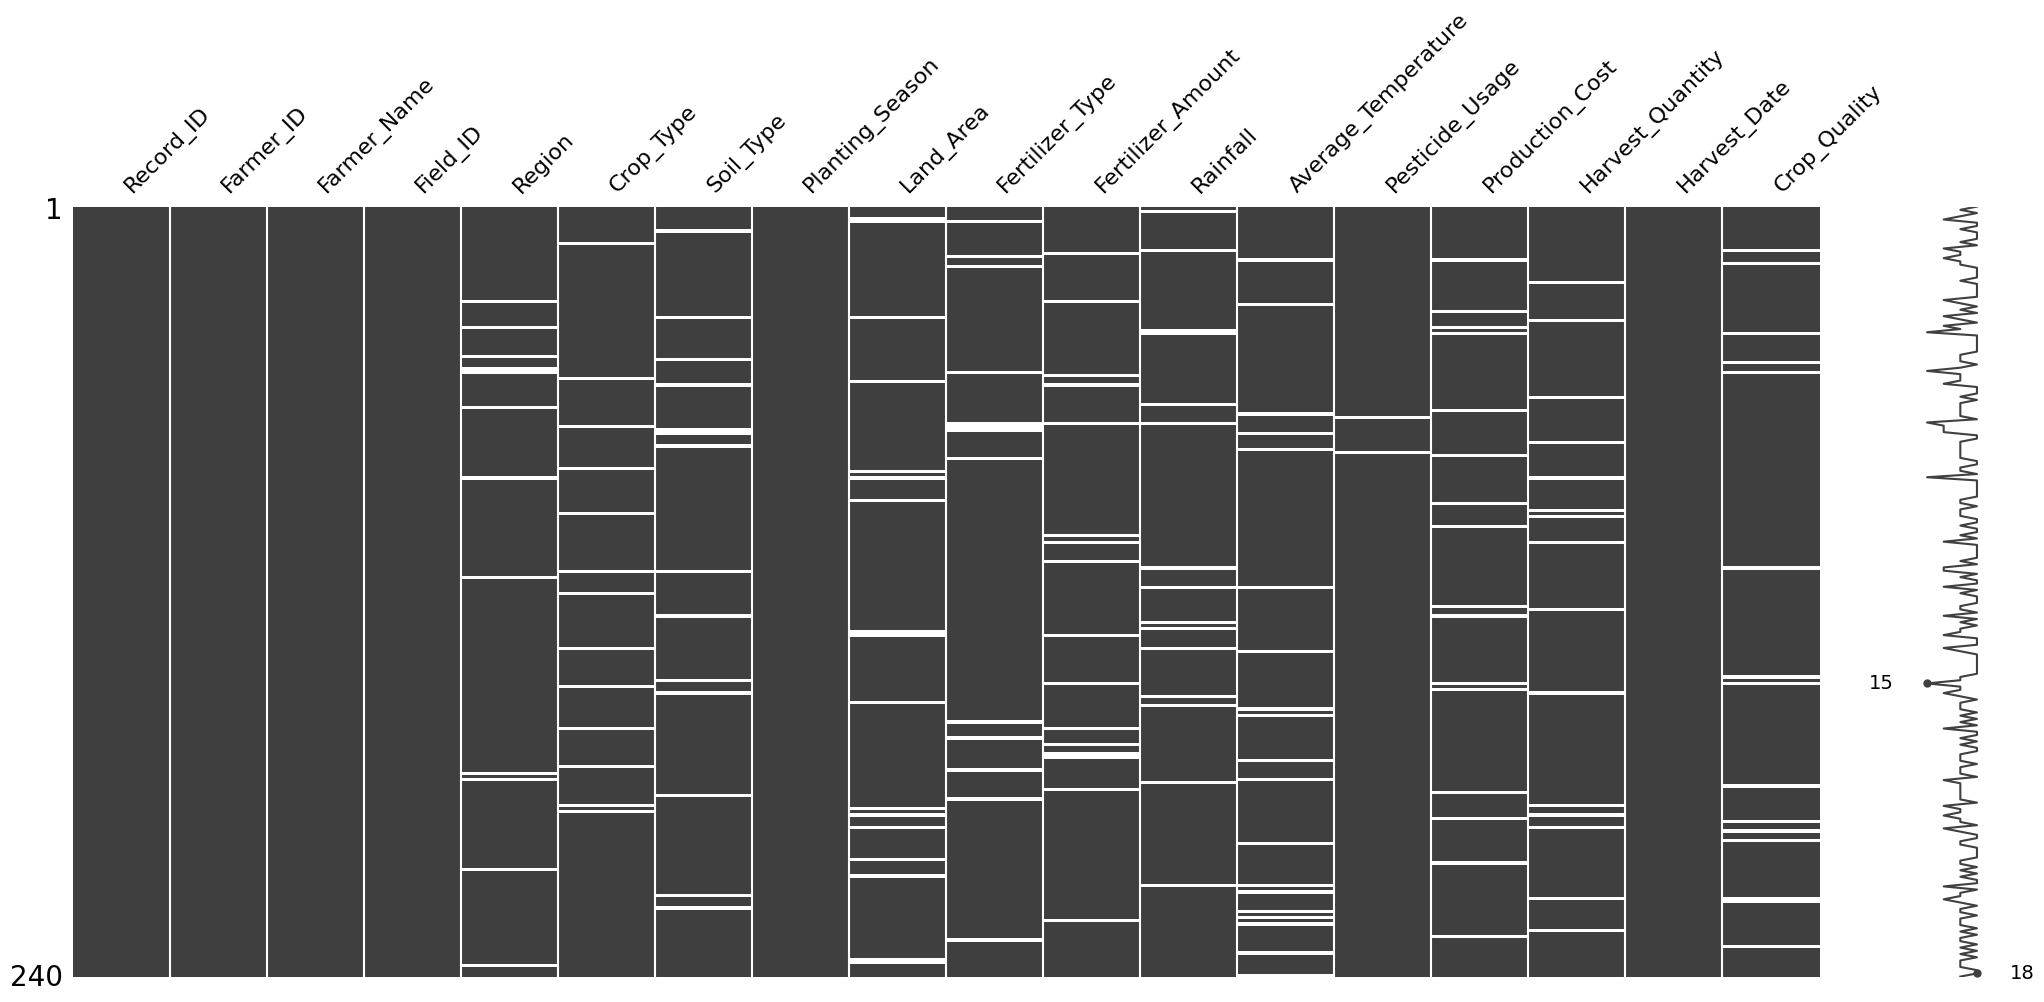

In [163]:
!pip install missingno
import missingno as msno

msno.matrix(data)

### Solusi 1: Omit the value

In [164]:
data_drop_row = data.dropna()
data_drop_row.shape

(108, 18)

In [165]:
data_drop_col = data.dropna(axis=1)
data_drop_col.shape

(240, 6)

### Solusi 2: Impute (statistik deskriptif)

In [166]:
data["Land_Area"].mean()

np.float64(2.857174887892377)

In [167]:
data["Land_Area"].median()

0.84

In [168]:
data["Land_Area"].mode()[0]

np.float64(0.64)

In [169]:
kolom_numerik = ["Land_Area", "Fertilizer_Amount", "Rainfall", "Average_Temperature",
                 "Pesticide_Usage", "Production_Cost", "Harvest_Quantity"]

tabel_stat = pd.DataFrame({
    "Mean"  : data[kolom_numerik].mean(),
    "Median": data[kolom_numerik].median(),
    "Modus" : data[kolom_numerik].mode().iloc[0],
    "Skewness": data[kolom_numerik].skew()
})
tabel_stat.round(2)

,Mean,Median,Modus,Skewness
Land_Area,2.86,0.84,0.64,9.46
Fertilizer_Amount,872.38,340.00,208.80,9.30
Rainfall,1022.05,779.70,1213.40,8.73
Average_Temperature,27.21,27.90,28.10,-1.09
Pesticide_Usage,5.87,3.45,2.10,3.76
Production_Cost,56447570.50,16510000.00,6070000.00,11.56
Harvest_Quantity,13361.35,5833.00,3663.00,9.53


In [170]:
data["Land_Area"] = data["Land_Area"].fillna(data["Land_Area"].median())

In [171]:
data["Fertilizer_Amount"] = data["Fertilizer_Amount"].fillna(data["Fertilizer_Amount"].median())

In [172]:
data["Rainfall"] = data["Rainfall"].fillna(data["Rainfall"].median())

In [173]:
data["Average_Temperature"] = data["Average_Temperature"].fillna(data["Average_Temperature"].mean())

In [174]:
data["Pesticide_Usage"] = data["Pesticide_Usage"].fillna(data["Pesticide_Usage"].median())

In [175]:
data["Production_Cost"] = data["Production_Cost"].fillna(data["Production_Cost"].median())

In [176]:
data["Harvest_Quantity"] = data["Harvest_Quantity"].fillna(data["Harvest_Quantity"].median())

In [177]:
data["Region"].mode()[0]

'Gresik'

In [178]:
data["Crop_Type"].mode()[0]

'Padi'

In [179]:
data["Soil_Type"].mode()[0]

'Lempung'

In [180]:
data["Fertilizer_Type"].mode()[0]

'ZA'

In [181]:
data["Crop_Quality"].mode()[0]

'Grade B'

In [182]:
data["Region"] = data["Region"].fillna(data["Region"].mode()[0])

In [183]:
data["Crop_Type"] = data["Crop_Type"].fillna(data["Crop_Type"].mode()[0])

In [184]:
data["Soil_Type"] = data["Soil_Type"].fillna(data["Soil_Type"].mode()[0])

In [185]:
data["Fertilizer_Type"] = data["Fertilizer_Type"].fillna(data["Fertilizer_Type"].mode()[0])

In [186]:
data["Crop_Quality"] = data["Crop_Quality"].fillna(data["Crop_Quality"].mode()[0])

### Output

## 1.5 Outlier

### a. Harvest_Quantity

### Deteksi

histogram

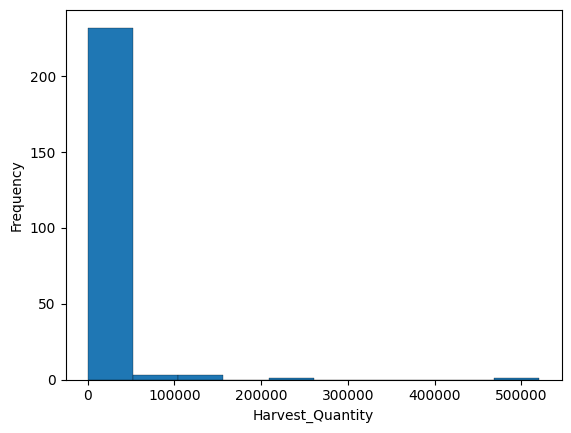

In [187]:
plt.hist(data["Harvest_Quantity"], edgecolor="black", linewidth=0.2)
plt.xlabel("Harvest_Quantity")
plt.ylabel("Frequency")
plt.show()

Boxplot

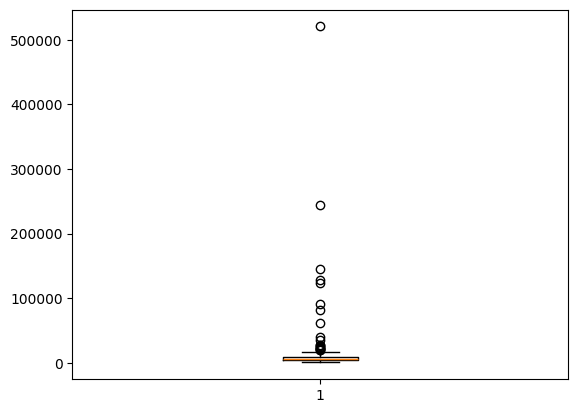

In [188]:
plt.boxplot(data["Harvest_Quantity"])
plt.show()

In [189]:
q1 = data["Harvest_Quantity"].quantile(0.25)
q3 = data["Harvest_Quantity"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
print(q1, q3, iqr, batas_bawah, batas_atas)

3940.25 9437.25 5497.0 -4305.25 17682.75


In [190]:
data[(data["Harvest_Quantity"] < batas_bawah) | (data["Harvest_Quantity"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
6,REC-0007,F002,Agus Maulana,L019,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.44,SP-36,796.0,869.2,27.3,12.0,52450000.0,520665.0,2026-01-22,Grade C
22,REC-0023,F062,Mariyam Hakim,L086,Jombang,Jagung,Lempung,Musim Hujan 2025/2026,2.47,NPK,833.1,1295.1,27.7,9.6,31260000.0,27839.0,2026-02-17,Grade C
33,REC-0034,F032,Kelompok Tani Makmur Jaya,L029,Bone,Jagung,Lempung,Musim Hujan 2025/2026,18.00,Urea,6752.8,943.2,28.1,29.5,166345000.0,145635.0,2026-02-27,Grade B
72,REC-0073,F070,Nasir Suryadi,L022,Malang,Tomat,Latosol,Musim Hujan 2025/2026,1.52,Organik,1026.0,1488.5,22.8,15.7,57815000.0,23561.0,2026-03-16,Grade C
85,REC-0086,F008,Kelompok Tani Sumber Rejeki,L008,Malang,Padi,Latosol,Musim Hujan 2025/2026,12.50,ZA,5155.3,1520.8,23.4,46.6,128270000.0,81929.0,2026-03-22,Grade A
89,REC-0090,F084,Suryani Prasetyo,L069,Gresik,Cabai,Aluvial,Musim Hujan 2025/2026,2.54,NPK,1696.9,1434.2,27.3,28.8,144350000.0,27922.0,2026-03-23,Grade B
103,REC-0104,F059,Kelompok Tani Tirto Rahayu,L088,Cianjur,Padi,Latosol,Musim Hujan 2025/2026,25.50,Urea,8243.6,2132.7,22.8,50.1,267485000.0,123169.0,2026-04-01,Grade C
120,REC-0121,F003,muhammad prasetyo,L066,Bantul,Padi,Aluvial,Musim Kemarau 2026,1.74,Organik,919.3,505.3,27.4,14.2,65045000.0,24037.0,2026-06-12,Grade A
133,REC-0134,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Kemarau 2026,0.84,SP-36,340.0,417.6,28.3,18.3,75935000.0,25294.0,2026-07-03,Grade A
134,REC-0135,F036,Lukman Santoso,L071,Bantul,Bawang Merah,Lempung,Musim Kemarau 2026,2.48,ZA,1746.4,420.9,27.3,26.1,131185000.0,34856.0,2026-07-06,Grade A


In [191]:
data["Harvest_Quantity"] = data["Harvest_Quantity"].clip(lower=batas_bawah, upper=batas_atas)

### Output

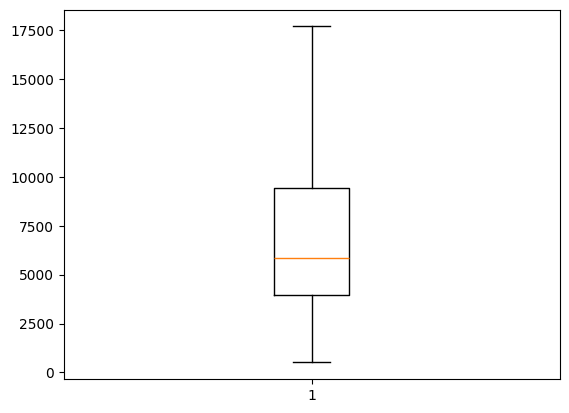

In [192]:
plt.boxplot(data["Harvest_Quantity"])
plt.show()

In [193]:
data["Harvest_Quantity"].max()

17682.75

b. Land_Area

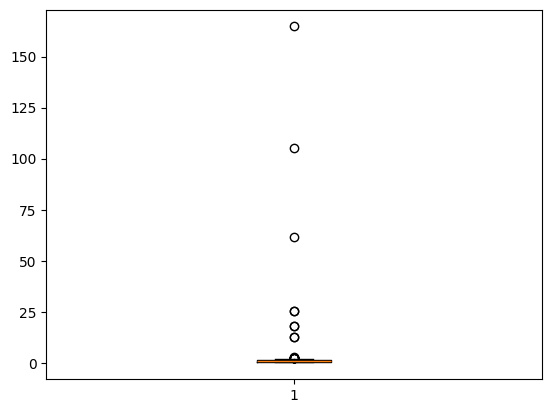

In [194]:
plt.boxplot(data["Land_Area"])
plt.show()

In [195]:
q1 = data["Land_Area"].quantile(0.25)
q3 = data["Land_Area"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
data[(data["Land_Area"] < batas_bawah) | (data["Land_Area"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
8,REC-0009,F075,nur saputra,L003,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,164.70,SP-36,1080.2,798.1,27.8,15.3,68230000.0,15956.00,2026-01-29,Grade C
18,REC-0019,F057,Samsul Kurniawan,L028,Cianjur,Jagung,Latosol,Musim Hujan 2025/2026,61.40,ZA,233.0,2034.1,22.6,2.1,7035000.0,3617.00,2026-02-15,Grade C
22,REC-0023,F062,Mariyam Hakim,L086,Jombang,Jagung,Lempung,Musim Hujan 2025/2026,2.47,NPK,833.1,1295.1,27.7,9.6,31260000.0,17682.75,2026-02-17,Grade C
33,REC-0034,F032,Kelompok Tani Makmur Jaya,L029,Bone,Jagung,Lempung,Musim Hujan 2025/2026,18.00,Urea,6752.8,943.2,28.1,29.5,166345000.0,17682.75,2026-02-27,Grade B
51,REC-0052,F050,Zainal Susanto,L039,Gresik,Padi,Aluvial,Musim Hujan 2025/2026,2.65,ZA,751.4,1185.3,29.6,4.7,29960000.0,13931.00,2026-03-07,Grade B
85,REC-0086,F008,Kelompok Tani Sumber Rejeki,L008,Malang,Padi,Latosol,Musim Hujan 2025/2026,12.50,ZA,5155.3,1520.8,23.4,46.6,128270000.0,17682.75,2026-03-22,Grade A
89,REC-0090,F084,Suryani Prasetyo,L069,Gresik,Cabai,Aluvial,Musim Hujan 2025/2026,2.54,NPK,1696.9,1434.2,27.3,28.8,144350000.0,17682.75,2026-03-23,Grade B
103,REC-0104,F059,Kelompok Tani Tirto Rahayu,L088,Cianjur,Padi,Latosol,Musim Hujan 2025/2026,25.50,Urea,8243.6,2132.7,22.8,50.1,267485000.0,17682.75,2026-04-01,Grade C
113,REC-0114,F049,Kasiman Yulianto,L005,Bone,Padi,Lempung,Musim Hujan 2025/2026,2.35,NPK,700.9,1213.4,28.3,8.0,31110000.0,12841.00,2026-04-08,Grade B
114,REC-0115,F036,Lukman Santoso,L071,Bantul,Padi,Lempung,Musim Hujan 2025/2026,2.48,ZA,782.2,1329.3,27.4,4.3,39745000.0,16318.00,2026-04-08,Grade B


In [196]:
data["Land_Area"] = data["Land_Area"].clip(lower=batas_bawah, upper=batas_atas)

### c. Fertilizer_Amount

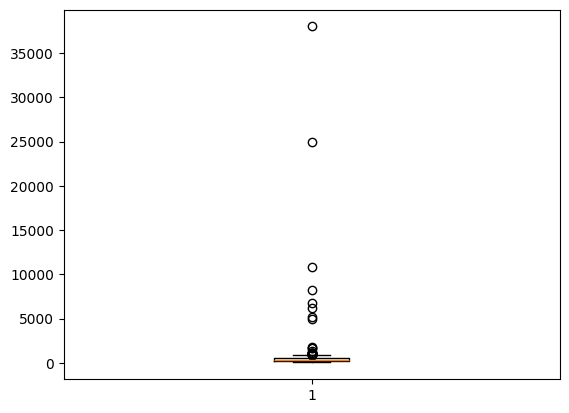

In [197]:
plt.boxplot(data["Fertilizer_Amount"])
plt.show()

In [198]:
q1 = data["Fertilizer_Amount"].quantile(0.25)
q3 = data["Fertilizer_Amount"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
data[(data["Fertilizer_Amount"] < batas_bawah) | (data["Fertilizer_Amount"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,0.8400,ZA,1089.6,809.4,27.6,15.0,69765000.0,13199.00,2026-01-18,Grade C
8,REC-0009,F075,nur saputra,L003,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,2.2025,SP-36,1080.2,798.1,27.8,15.3,68230000.0,15956.00,2026-01-29,Grade C
9,REC-0010,F071,Mariyam Saputra,L044,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.7900,Organik,1129.3,546.2,28.3,18.3,95480000.0,16750.00,2026-01-31,Grade C
33,REC-0034,F032,Kelompok Tani Makmur Jaya,L029,Bone,Jagung,Lempung,Musim Hujan 2025/2026,2.2025,Urea,6752.8,943.2,28.1,29.5,166345000.0,17682.75,2026-02-27,Grade B
45,REC-0046,F040,BAMBANG PRASETYO,L103,Bone,Padi,Liat,Musim Hujan 2025/2026,1.3000,Urea,933.2,907.6,27.5,4.3,14665000.0,7582.00,2026-03-05,Grade B
56,REC-0057,F034,Andi Santoso,L006,Lamongan,Cabai,Aluvial,Musim Hujan 2025/2026,0.2000,Organik,38000.0,1511.8,27.1,2.6,11685000.0,1528.00,2026-03-11,Grade C
66,REC-0067,F028,Rohmat Hakim,L063,Banyuwangi,Cabai,Aluvial,Musim Hujan 2025/2026,1.2000,Organik,970.9,17948.7,27.0,15.4,59415000.0,11710.00,2026-03-14,Grade C
72,REC-0073,F070,Nasir Suryadi,L022,Malang,Tomat,Latosol,Musim Hujan 2025/2026,1.5200,Organik,1026.0,1488.5,22.8,15.7,57815000.0,17682.75,2026-03-16,Grade C
73,REC-0074,F011,Nur Kurniawan,L036,Jombang,Padi,Lempung,Musim Hujan 2025/2026,1.4200,ZA,25000.0,1291.2,27.6,3.4,20525000.0,5833.00,2026-03-16,Grade B
85,REC-0086,F008,Kelompok Tani Sumber Rejeki,L008,Malang,Padi,Latosol,Musim Hujan 2025/2026,2.2025,ZA,5155.3,1520.8,23.4,46.6,128270000.0,17682.75,2026-03-22,Grade A


In [199]:
data["Fertilizer_Amount"] = data["Fertilizer_Amount"].clip(lower=batas_bawah, upper=batas_atas)

### d. Rainfall

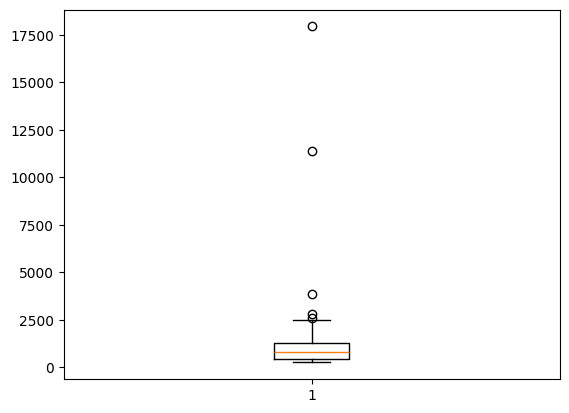

In [200]:
plt.boxplot(data["Rainfall"])
plt.show()

In [201]:
q1 = data["Rainfall"].quantile(0.25)
q3 = data["Rainfall"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
data[(data["Rainfall"] < batas_bawah) | (data["Rainfall"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
40,REC-0041,F031,Sutrisno Saputra,L013,Malang,Tomat,Lempung,Musim Hujan 2025/2026,0.68,NPK,352.2000,3829.3,23.8,5.0,39690000.0,9853.0,2026-03-04,Grade C
66,REC-0067,F028,Rohmat Hakim,L063,Banyuwangi,Cabai,Aluvial,Musim Hujan 2025/2026,1.20,Organik,889.7375,17948.7,27.0,15.4,59415000.0,11710.0,2026-03-14,Grade C
80,REC-0081,F074,Nur Susanto,L093,Indramayu,Padi,Aluvial,Musim Hujan 2025/2026,0.62,Urea,241.2000,11390.7,29.9,1.3,10215000.0,4069.0,2026-03-20,Grade B
82,REC-0083,F046,Yusuf Susanto,L027,Gresik,Jagung,Lempung,Musim Hujan 2025/2026,0.84,Urea,252.7000,2799.6,28.9,2.2,6150000.0,4725.0,2026-03-21,Grade B
117,REC-0118,F021,Ridwan Purwanto,L047,Cianjur,Cabai,Lempung,Musim Hujan 2025/2026,0.92,ZA,782.8000,2583.5,23.7,8.9,44505000.0,8825.0,2026-04-10,Grade C


In [202]:
data["Rainfall"] = data["Rainfall"].clip(lower=batas_bawah, upper=batas_atas)

### e. Pesticide_Usage

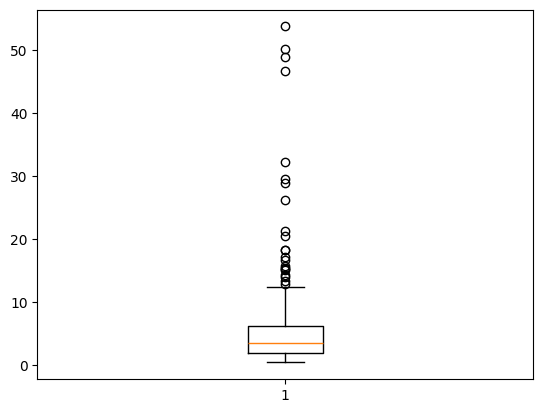

In [203]:
plt.boxplot(data["Pesticide_Usage"])
plt.show()

In [204]:
q1 = data["Pesticide_Usage"].quantile(0.25)
q3 = data["Pesticide_Usage"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
data[(data["Pesticide_Usage"] < batas_bawah) | (data["Pesticide_Usage"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
1,REC-0002,F009,Sumarni Ramadhan,L095,Gresik,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.5000,ZA,738.9000,779.70,28.3,13.3,79275000.0,11271.00,2026-01-12,Grade C
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,0.8400,ZA,889.7375,809.40,27.6,15.0,69765000.0,13199.00,2026-01-18,Grade C
8,REC-0009,F075,nur saputra,L003,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,2.2025,SP-36,889.7375,798.10,27.8,15.3,68230000.0,15956.00,2026-01-29,Grade C
9,REC-0010,F071,Mariyam Saputra,L044,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.7900,Organik,889.7375,546.20,28.3,18.3,95480000.0,16750.00,2026-01-31,Grade C
33,REC-0034,F032,Kelompok Tani Makmur Jaya,L029,Bone,Jagung,Lempung,Musim Hujan 2025/2026,2.2025,Urea,889.7375,943.20,28.1,29.5,166345000.0,17682.75,2026-02-27,Grade B
66,REC-0067,F028,Rohmat Hakim,L063,Banyuwangi,Cabai,Aluvial,Musim Hujan 2025/2026,1.2000,Organik,889.7375,2583.05,27.0,15.4,59415000.0,11710.00,2026-03-14,Grade C
72,REC-0073,F070,Nasir Suryadi,L022,Malang,Tomat,Latosol,Musim Hujan 2025/2026,1.5200,Organik,889.7375,1488.50,22.8,15.7,57815000.0,17682.75,2026-03-16,Grade C
85,REC-0086,F008,Kelompok Tani Sumber Rejeki,L008,Malang,Padi,Latosol,Musim Hujan 2025/2026,2.2025,ZA,889.7375,1520.80,23.4,46.6,128270000.0,17682.75,2026-03-22,Grade A
89,REC-0090,F084,Suryani Prasetyo,L069,Gresik,Cabai,Aluvial,Musim Hujan 2025/2026,2.2025,NPK,889.7375,1434.20,27.3,28.8,144350000.0,17682.75,2026-03-23,Grade B
103,REC-0104,F059,Kelompok Tani Tirto Rahayu,L088,Cianjur,Padi,Latosol,Musim Hujan 2025/2026,2.2025,Urea,889.7375,2132.70,22.8,50.1,267485000.0,17682.75,2026-04-01,Grade C


In [205]:
data["Pesticide_Usage"] = data["Pesticide_Usage"].clip(lower=batas_bawah, upper=batas_atas)

### f. Production_Cost

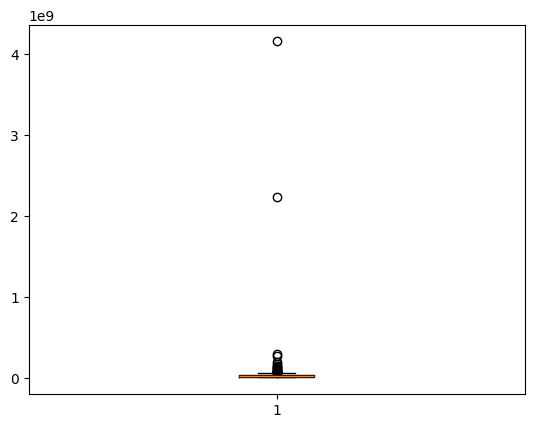

In [206]:
plt.boxplot(data["Production_Cost"])
plt.show()

In [207]:
q1 = data["Production_Cost"].quantile(0.25)
q3 = data["Production_Cost"].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr
data[(data["Production_Cost"] < batas_bawah) | (data["Production_Cost"] > batas_atas)]

,Record_ID,Farmer_ID,Farmer_Name,Field_ID,Region,Crop_Type,Soil_Type,Planting_Season,Land_Area,Fertilizer_Type,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity,Harvest_Date,Crop_Quality
1,REC-0002,F009,Sumarni Ramadhan,L095,Gresik,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.5000,ZA,738.9000,779.7,28.30000,12.775,7.927500e+07,11271.00,2026-01-12,Grade C
4,REC-0005,F052,Bambang Kurniawan,L026,Gresik,Bawang Merah,Liat,Musim Hujan 2025/2026,0.8400,ZA,889.7375,809.4,27.60000,12.775,6.976500e+07,13199.00,2026-01-18,Grade C
8,REC-0009,F075,nur saputra,L003,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,2.2025,SP-36,889.7375,798.1,27.80000,12.775,6.823000e+07,15956.00,2026-01-29,Grade C
9,REC-0010,F071,Mariyam Saputra,L044,Brebes,Bawang Merah,Lempung,Musim Hujan 2025/2026,1.7900,Organik,889.7375,546.2,28.30000,12.775,9.548000e+07,16750.00,2026-01-31,Grade C
15,REC-0016,F064,Fadli Wibowo,L101,Indramayu,Bawang Merah,Aluvial,Musim Hujan 2025/2026,0.9900,ZA,440.3000,869.0,28.50000,9.500,4.156885e+09,10519.00,2026-02-07,Grade B
23,REC-0024,F043,Ahmad Maulana,L112,Cianjur,Tomat,Lempung,Musim Hujan 2025/2026,0.4600,SP-36,310.1000,2012.8,24.20000,3.800,2.230293e+09,5833.00,2026-02-17,Grade C
33,REC-0034,F032,Kelompok Tani Makmur Jaya,L029,Bone,Jagung,Lempung,Musim Hujan 2025/2026,2.2025,Urea,889.7375,943.2,28.10000,12.775,1.663450e+08,17682.75,2026-02-27,Grade B
85,REC-0086,F008,Kelompok Tani Sumber Rejeki,L008,Malang,Padi,Latosol,Musim Hujan 2025/2026,2.2025,ZA,889.7375,1520.8,23.40000,12.775,1.282700e+08,17682.75,2026-03-22,Grade A
89,REC-0090,F084,Suryani Prasetyo,L069,Gresik,Cabai,Aluvial,Musim Hujan 2025/2026,2.2025,NPK,889.7375,1434.2,27.30000,12.775,1.443500e+08,17682.75,2026-03-23,Grade B
103,REC-0104,F059,Kelompok Tani Tirto Rahayu,L088,Cianjur,Padi,Latosol,Musim Hujan 2025/2026,2.2025,Urea,889.7375,2132.7,22.80000,12.775,2.674850e+08,17682.75,2026-04-01,Grade C


In [302]:
data["Production_Cost"] = data["Production_Cost"].clip(lower=batas_bawah, upper=batas_atas)

### g. Average_Temperature

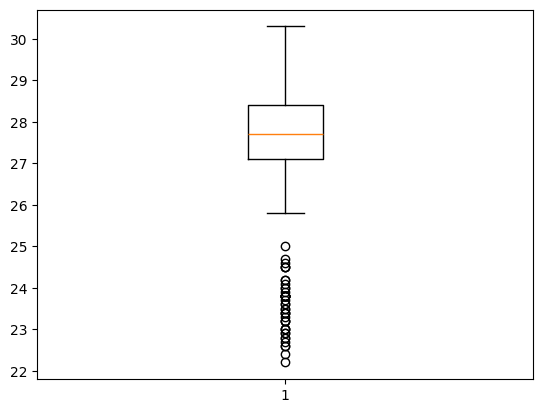

In [209]:
plt.boxplot(data["Average_Temperature"])
plt.show()

Output

In [210]:
kolom_numerik = ["Land_Area", "Fertilizer_Amount", "Rainfall", "Average_Temperature",
                 "Pesticide_Usage", "Production_Cost", "Harvest_Quantity"]

In [211]:
data[kolom_numerik].describe().round(2)

,Land_Area,Fertilizer_Amount,Rainfall,Average_Temperature,Pesticide_Usage,Production_Cost,Harvest_Quantity
count,240.00,240.00,240.00,240.00,240.00,240.00,240.00
mean,0.94,408.74,900.09,27.21,4.75,23063952.61,7260.67
std,0.52,244.57,568.69,1.91,3.75,17853119.73,4678.42
min,0.20,41.30,247.40,22.20,0.40,1445000.00,508.00
25%,0.54,232.92,410.68,27.10,1.90,10230000.00,3940.25
50%,0.84,340.00,779.70,27.70,3.45,16510000.00,5833.00
75%,1.20,495.65,1279.62,28.40,6.25,31147500.00,9437.25
max,2.20,889.74,2583.05,30.30,12.77,62523750.00,17682.75


## 1.6 Duplikat

Deteksi

In [212]:
data.duplicated().sum()

np.int64(0)

In [213]:
# Record_ID seharusnya unik (primary key)
data["Record_ID"].duplicated().sum()

np.int64(0)

### Solusi

In [214]:
data = data.drop_duplicates(subset="Record_ID")

### Output

In [215]:
data.shape

(240, 18)

In [216]:
data.to_csv("dataset_bersih.csv", index=False)

# **2 Data Transformation**

2.1 Normalization

In [217]:
data_norm = data.copy()

a. Decimal scaling

In [218]:
data["Harvest_Quantity"].max()

17682.75

In [219]:
k = len(str(int(data["Harvest_Quantity"].abs().max())))
k

5

In [220]:
data_norm["Harvest_decimal"] = data["Harvest_Quantity"] / 10**k

In [221]:
data_norm["Harvest_decimal"].describe()

,Harvest_decimal
count,240.000000
mean,0.072607
std,0.046784
min,0.005080
25%,0.039403
50%,0.058330
75%,0.094372
max,0.176827


### b. Min-max normalization

In [222]:
data_norm["Harvest_minmax"] = (data["Harvest_Quantity"] - data["Harvest_Quantity"].min()) / (data["Harvest_Quantity"].max() - data["Harvest_Quantity"].min())

In [223]:
from sklearn.preprocessing import MinMaxScaler

data_norm["Harvest_minmax_sk"] = MinMaxScaler().fit_transform(data[["Harvest_Quantity"]])

In [224]:
data_norm[["Harvest_Quantity", "Harvest_minmax", "Harvest_minmax_sk"]].head()

,Harvest_Quantity,Harvest_minmax,Harvest_minmax_sk
0,8634.0,0.473136,0.473136
1,11271.0,0.626676,0.626676
2,9144.0,0.502831,0.502831
3,5127.0,0.268941,0.268941
4,13199.0,0.738934,0.738934


### c. Standard deviation (z-score)

In [225]:
data_norm["Harvest_zscore"] = (data["Harvest_Quantity"] - data["Harvest_Quantity"].mean()) / data["Harvest_Quantity"].std()

In [226]:
from sklearn.preprocessing import StandardScaler

data_norm["Harvest_zscore_sk"] = StandardScaler().fit_transform(data[["Harvest_Quantity"]])

In [227]:
data_norm[["Harvest_Quantity", "Harvest_zscore", "Harvest_zscore_sk"]].head()

,Harvest_Quantity,Harvest_zscore,Harvest_zscore_sk
0,8634.0,0.293546,0.294160
1,11271.0,0.857198,0.858990
2,9144.0,0.402558,0.403399
3,5127.0,-0.456066,-0.457019
4,13199.0,1.269303,1.271956


### d. Robust scaling

In [228]:
q1 = data["Harvest_Quantity"].quantile(0.25)
q3 = data["Harvest_Quantity"].quantile(0.75)
iqr = q3 - q1
data_norm["Harvest_robust"] = (data["Harvest_Quantity"] - data["Harvest_Quantity"].median()) / iqr

Dengan RobustScaler

In [229]:
from sklearn.preprocessing import RobustScaler

data_norm["Harvest_robust_sk"] = RobustScaler().fit_transform(data[["Harvest_Quantity"]])

### Output

In [230]:
data_norm[["Harvest_Quantity", "Harvest_decimal", "Harvest_minmax", "Harvest_zscore", "Harvest_robust"]].describe().round(3)

,Harvest_Quantity,Harvest_decimal,Harvest_minmax,Harvest_zscore,Harvest_robust
count,240.000,240.000,240.000,240.000,240.000
mean,7260.667,0.073,0.393,-0.000,0.260
std,4678.420,0.047,0.272,1.000,0.851
min,508.000,0.005,0.000,-1.443,-0.969
25%,3940.250,0.039,0.200,-0.710,-0.344
50%,5833.000,0.058,0.310,-0.305,0.000
75%,9437.250,0.094,0.520,0.465,0.656
max,17682.750,0.177,1.000,2.228,2.156


### **2.2 Encoding**

### a. One-hot encoding (kategori nominal)

In [231]:
data["Soil_Type"].unique()

array(['Lempung', 'Aluvial', 'Liat', 'Latosol', 'Pasir'], dtype=object)

In [232]:
data_enc = pd.get_dummies(data, columns=["Soil_Type"])

In [233]:
data_enc.filter(like="Soil_Type").head()

,Soil_Type_Aluvial,Soil_Type_Latosol,Soil_Type_Lempung,Soil_Type_Liat,Soil_Type_Pasir
0,False,False,True,False,False
1,False,False,True,False,False
2,True,False,False,False,False
3,True,False,False,False,False
4,False,False,False,True,False


### b. Label encoding (kategori ordinal)

In [234]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
data_enc["Quality_encoded"] = label_encoder.fit_transform(data["Crop_Quality"])

In [235]:
data_enc[["Crop_Quality", "Quality_encoded"]].drop_duplicates()

,Crop_Quality,Quality_encoded
0,Grade C,2
2,Grade A,0
7,Grade B,1


### **4.3 Discretization**

### a. Equal-width binning

In [236]:
data_diskrit = data.copy()

In [237]:
data_diskrit["Rainfall_Bin"] = pd.cut(data["Rainfall"], bins=3, labels=["Low", "Medium", "High"])

In [238]:
data_diskrit[["Rainfall", "Rainfall_Bin"]].head()

,Rainfall,Rainfall_Bin
0,854.4,Low
1,779.7,Low
2,812.0,Low
3,946.8,Low
4,809.4,Low


In [239]:
data_diskrit["Rainfall_Bin"].value_counts()

,count
Rainfall_Bin,
Low,150
Medium,71
High,19


### b. Equal-frequency binning

In [240]:
data_diskrit["Harvest_Quantile"] = pd.qcut(data["Harvest_Quantity"], q=3, labels=["Low", "Medium", "High"])

In [241]:
data_diskrit[["Harvest_Quantity", "Harvest_Quantile"]].head()

,Harvest_Quantity,Harvest_Quantile
0,8634.0,High
1,11271.0,High
2,9144.0,High
3,5127.0,Medium
4,13199.0,High


In [242]:
data_diskrit["Harvest_Quantile"].value_counts()

,count
Harvest_Quantile,
Low,80
Medium,80
High,80


### c. Batas ditentukan sendiri

In [243]:
data_diskrit["Land_Category"] = pd.cut(data["Land_Area"], bins=[0, 0.5, 1.5, np.inf], labels=["Sempit", "Sedang", "Luas"])

In [244]:
data_diskrit["Land_Category"].value_counts()

,count
Land_Category,
Sedang,150
Sempit,54
Luas,36


## **2.4 Measurement**

### a. Curah hujan: sentimeter dan milimeter

Input

In [245]:
hujan_mm = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/curah_hujan_mm.csv")

In [246]:
hujan_cm = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/curah_hujan_cm.csv")

### Deteksi

In [247]:
hujan_mm.head()

,Station_ID,Region,Tahun_Bulan,Curah_Hujan_mm
0,ST-GRE,Gresik,2025-01,393.4
1,ST-GRE,Gresik,2025-02,207.7
2,ST-GRE,Gresik,2025-03,267.4
3,ST-GRE,Gresik,2025-04,215.7
4,ST-GRE,Gresik,2025-05,113.7


In [248]:
hujan_cm.head()

,Station_ID,Region,Tahun_Bulan,Curah_Hujan_cm
0,ST-KAR,Karawang,2025-01,34.04
1,ST-KAR,Karawang,2025-02,25.43
2,ST-KAR,Karawang,2025-03,29.76
3,ST-KAR,Karawang,2025-04,22.91
4,ST-KAR,Karawang,2025-05,17.74


In [249]:
hujan_mm["Curah_Hujan_mm"].describe()

,Curah_Hujan_mm
count,154.000000
mean,181.283766
std,125.833179
min,26.300000
25%,66.600000
50%,144.600000
75%,272.300000
max,644.900000


In [250]:
hujan_cm["Curah_Hujan_cm"].describe()

,Curah_Hujan_cm
count,110.000000
mean,19.019182
std,14.383350
min,2.510000
25%,6.855000
50%,14.750000
75%,29.080000
max,73.230000


In [251]:
hujan_cm["Curah_Hujan_mm"] = hujan_cm["Curah_Hujan_cm"] * 10

In [252]:
hujan_cm = hujan_cm.drop(columns="Curah_Hujan_cm")

### Output

In [253]:
hujan_cm.head()

,Station_ID,Region,Tahun_Bulan,Curah_Hujan_mm
0,ST-KAR,Karawang,2025-01,340.4
1,ST-KAR,Karawang,2025-02,254.3
2,ST-KAR,Karawang,2025-03,297.6
3,ST-KAR,Karawang,2025-04,229.1
4,ST-KAR,Karawang,2025-05,177.4


### b. Penggunaan pupuk: gram dan kilogram

### Input

In [254]:
pupuk_kg = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/penggunaan_pupuk_kg.csv")

In [255]:
pupuk_gram = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/penggunaan_pupuk_gram.csv")

Deteksi

In [256]:
pupuk_kg.head()

,Record_ID,Fertilizer_Type,Fertilizer_Amount_kg
0,REC-0001,NPK,648.6
1,REC-0003,ZA,420.8
2,REC-0005,Organik,1089.6
3,REC-0007,SP-36,796.0
4,REC-0009,SP-36,1080.2


In [257]:
pupuk_gram.head()

,Record_ID,Fertilizer_Type,Fertilizer_Amount_gram
0,REC-0002,ZA,738900
1,REC-0004,SP-36,202900
2,REC-0006,SP-36,366600
3,REC-0008,SP-36,184900
4,REC-0010,Organik,1129300


In [258]:
pupuk_kg["Fertilizer_Amount_kg"].describe()

,Fertilizer_Amount_kg
count,120.000000
mean,528.730833
std,1078.564421
min,41.300000
25%,204.950000
50%,319.600000
75%,495.800000
max,10874.200000


In [259]:
pupuk_gram["Fertilizer_Amount_gram"].describe()

,Fertilizer_Amount_gram
count,1.200000e+02
mean,6.163217e+05
std,1.164911e+06
min,7.530000e+04
25%,2.167000e+05
50%,3.658500e+05
75%,4.989500e+05
max,8.243600e+06


### Solusi

In [260]:
pupuk_gram["Fertilizer_Amount_kg"] = pupuk_gram["Fertilizer_Amount_gram"] / 1000

In [261]:
pupuk_gram = pupuk_gram.drop(columns="Fertilizer_Amount_gram")

### Output

In [262]:
pupuk_gram.head()

,Record_ID,Fertilizer_Type,Fertilizer_Amount_kg
0,REC-0002,ZA,738.9
1,REC-0004,SP-36,202.9
2,REC-0006,SP-36,366.6
3,REC-0008,SP-36,184.9
4,REC-0010,Organik,1129.3


### 2.5 Aggregation

In [263]:
harian = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/produksi_harian.csv")

In [264]:
mingguan = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/produksi_mingguan.csv")

### Deteksi

In [265]:
harian.head()

,Record_ID,Farmer_ID,Field_ID,Crop_Type,Tanggal,Hasil_Panen_kg
0,REC-0073,F070,L022,Tomat,2026-03-16,2984
1,REC-0073,F070,L022,Tomat,2026-03-17,4294
2,REC-0073,F070,L022,Tomat,2026-03-18,2629
3,REC-0073,F070,L022,Tomat,2026-03-19,3789
4,REC-0073,F070,L022,Tomat,2026-03-20,2306


In [266]:
mingguan.head()

,Record_ID,Farmer_ID,Field_ID,Crop_Type,Tahun,Minggu_Ke,Tanggal_Awal_Minggu,Hasil_Panen_kg
0,REC-0126,F061,L059,Bawang Merah,2026,26,2026-06-22,395
1,REC-0126,F061,L059,Bawang Merah,2026,27,2026-06-29,1200
2,REC-0126,F061,L059,Bawang Merah,2026,28,2026-07-06,1802
3,REC-0126,F061,L059,Bawang Merah,2026,29,2026-07-13,1100
4,REC-0126,F061,L059,Bawang Merah,2026,30,2026-07-20,485


In [267]:
harian.shape

(410, 6)

### Solusi

In [268]:
harian["Tanggal"] = pd.to_datetime(harian["Tanggal"])

In [269]:
harian["Tanggal_Awal_Minggu"] = harian["Tanggal"] - pd.to_timedelta(harian["Tanggal"].dt.weekday, unit="D")

In [270]:
harian["Tahun"] = harian["Tanggal"].dt.isocalendar().year.astype(int)
harian["Minggu_Ke"] = harian["Tanggal"].dt.isocalendar().week.astype(int)

In [271]:
harian_mingguan = harian.groupby(["Record_ID", "Farmer_ID", "Field_ID", "Crop_Type", "Tahun", "Minggu_Ke", "Tanggal_Awal_Minggu"], as_index=False)["Hasil_Panen_kg"].sum()

### Output

In [272]:
harian_mingguan.head()

,Record_ID,Farmer_ID,Field_ID,Crop_Type,Tahun,Minggu_Ke,Tanggal_Awal_Minggu,Hasil_Panen_kg
0,REC-0044,F081,L049,Tomat,2026,10,2026-03-02,5119
1,REC-0044,F081,L049,Tomat,2026,11,2026-03-09,3254
2,REC-0044,F081,L049,Tomat,2026,12,2026-03-16,304
3,REC-0057,F034,L006,Cabai,2026,11,2026-03-09,799
4,REC-0057,F034,L006,Cabai,2026,12,2026-03-16,675


In [273]:
harian.shape, harian_mingguan.shape

((410, 9), (76, 8))

## Data Integration

### Joining Table

In [274]:
produksi = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/data_produksi.csv")

In [275]:
petani = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/data_petani_lahan.csv")

In [276]:
produksi.shape

(240, 9)

In [277]:
petani.shape

(126, 6)

### Inner join

In [278]:
inner_merged = pd.merge(produksi, petani, how="inner", on=["Farmer_ID", "Field_ID"])
inner_merged.shape

(233, 13)

### Left join

In [279]:
left_merged = pd.merge(produksi, petani, how="left", on=["Farmer_ID", "Field_ID"])
left_merged.shape

(240, 13)

### Output

In [280]:
left_merged.head()

,Record_ID,Farmer_ID,Field_ID,Crop_Type,Planting_Season,Fertilizer_Type,Fertilizer_Amount,Harvest_Quantity,Production_Cost,Farmer_Name,Region,Soil_Type,Land_Area
0,REC-0001,F014,L084,Bawang Merah,Musim Hujan 2025/2026,NPK,648.6,8634,38585000,Sumarni Yulianto,Bantul,Lempung,0.90
1,REC-0002,F009,L095,Bawang Merah,Musim Hujan 2025/2026,ZA,738.9,11271,79275000,Sumarni Ramadhan,Gresik,Lempung,1.50
2,REC-0003,F015,L021,Bawang Merah,Musim Hujan 2025/2026,ZA,420.8,9144,26325000,Tukijan Rahayu,Brebes,Aluvial,0.72
3,REC-0004,F036,L078,Bawang Merah,Musim Hujan 2025/2026,SP-36,202.9,5127,28130000,Lukman Santoso,Bantul,Aluvial,0.54
4,REC-0005,F052,L026,Bawang Merah,Musim Hujan 2025/2026,Organik,1089.6,13199,69765000,Bambang Kurniawan,Gresik,Liat,1.58


In [281]:
left_merged[left_merged["Farmer_Name"].isnull()]

,Record_ID,Farmer_ID,Field_ID,Crop_Type,Planting_Season,Fertilizer_Type,Fertilizer_Amount,Harvest_Quantity,Production_Cost,Farmer_Name,Region,Soil_Type,Land_Area
7,REC-0008,F048,L050,Bawang Merah,Musim Hujan 2025/2026,SP-36,184.9,3105,12540000,NaN,NaN,NaN,NaN
17,REC-0018,F048,L035,Bawang Merah,Musim Hujan 2025/2026,SP-36,421.3,6066,22965000,NaN,NaN,NaN,NaN
28,REC-0029,F026,L081,Jagung,Musim Hujan 2025/2026,Urea,162.7,2677,5115000,NaN,NaN,NaN,NaN
151,REC-0152,F048,L050,Bawang Merah,Musim Kemarau 2026,NPK,209.3,3963,16125000,NaN,NaN,NaN,NaN
182,REC-0183,F048,L035,Padi,Musim Kemarau 2026,ZA,192.0,2475,8105000,NaN,NaN,NaN,NaN
189,REC-0190,F026,L081,Padi,Musim Kemarau 2026,ZA,140.9,2144,5190000,NaN,NaN,NaN,NaN
238,REC-0239,F067,L110,Cabai,Musim Kemarau 2026,NPK,183.5,1955,10935000,NaN,NaN,NaN,NaN


### **Appending Table**

### a. Produksi Musim 1 dan Musim 2

### Input

In [282]:
musim1 = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/Produksi_Pertanian_Musim_1.csv")

In [283]:
musim2 = pd.read_csv("https://raw.githubusercontent.com/abdulazis703/data_preprocessing_pertanian_industri/refs/heads/main/dataset%20pertanian/Produksi_Pertanian_Musim_2.csv")

In [284]:
musim1.columns.tolist() == musim2.columns.tolist()

True

Proses

In [285]:
produksi_musim = pd.concat([musim1, musim2], ignore_index=True)

### Output

In [286]:
produksi_musim.shape

(240, 10)

In [287]:
produksi_musim["Planting_Season"].value_counts()

,count
Planting_Season,
Musim Hujan 2025/2026,120
Musim Kemarau 2026,120


In [288]:
produksi_musim["Record_ID"].duplicated().sum()

np.int64(0)

### b. Curah hujan (setelah satuan disamakan)

### Proses

In [289]:
hujan = pd.concat([hujan_mm, hujan_cm], ignore_index=True)

### Output

In [290]:
hujan.shape

(264, 4)

In [291]:
hujan["Region"].value_counts()

,count
Region,
Gresik,22
Lamongan,22
Sidoarjo,22
Jombang,22
Malang,22
Banyuwangi,22
Bantul,22
Karawang,22
Indramayu,22


In [292]:
hujan.duplicated(subset=["Region", "Tahun_Bulan"]).sum()

np.int64(0)

### c. Penggunaan pupuk (setelah satuan disamakan)

### Proses

In [293]:
pupuk = pd.concat([pupuk_kg, pupuk_gram], ignore_index=True)

Output

In [294]:
pupuk.shape

(240, 3)

In [295]:
pupuk["Record_ID"].duplicated().sum()

np.int64(0)

### d. Produksi harian dan mingguan (setelah tingkat agregasinya disamakan)

### Proses

In [296]:
mingguan["Tanggal_Awal_Minggu"] = pd.to_datetime(mingguan["Tanggal_Awal_Minggu"])

In [297]:
produksi_gabung = pd.concat([harian_mingguan, mingguan], ignore_index=True)

In [298]:
produksi_gabung = produksi_gabung.sort_values(["Record_ID", "Tanggal_Awal_Minggu"]).reset_index(drop=True)

### Output

In [299]:
produksi_gabung.shape

(169, 8)

In [300]:
produksi_gabung["Record_ID"].nunique()

40

In [301]:
produksi_gabung.duplicated(subset=["Record_ID", "Tanggal_Awal_Minggu"]).sum()

np.int64(0)